# Library

In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from google.colab import drive

In [168]:
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Machine Learning/titanic_train.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Data

In [169]:
print('data head:')
print(df.head())

data head:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN   

In [170]:
print('data info:')
print(df.info())

data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [171]:
print('data describe:')
print(df.describe())

data describe:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [172]:
print('null data:')
print(df.isnull().sum())

null data:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [173]:
print('duplicate data:', df.duplicated().sum())

duplicate data: 0


# Data Distribution

In [174]:
sns.set_style('whitegrid')

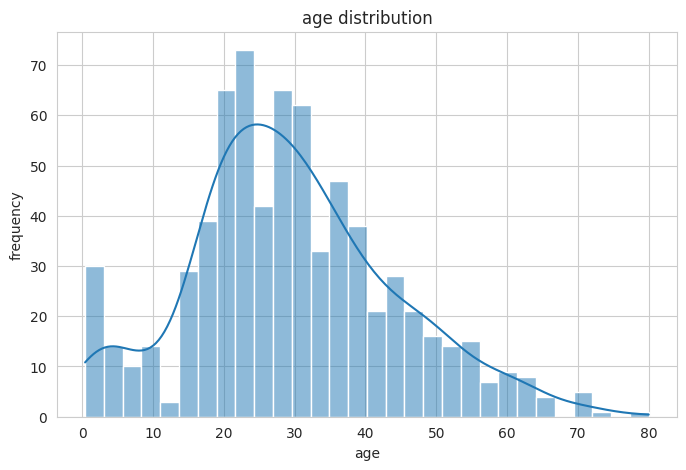

<ipython-input-175-c96a9dc61f59>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Age'], palette='crest')


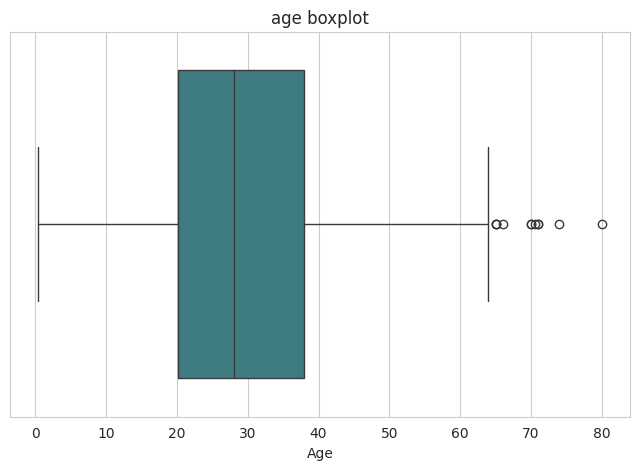

In [175]:
# age
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], kde=True, bins=30)
plt.title("age distribution")
plt.xlabel("age")
plt.ylabel("frequency")
plt.show()

print()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Age'], palette='crest')
plt.title('age boxplot')
plt.show()

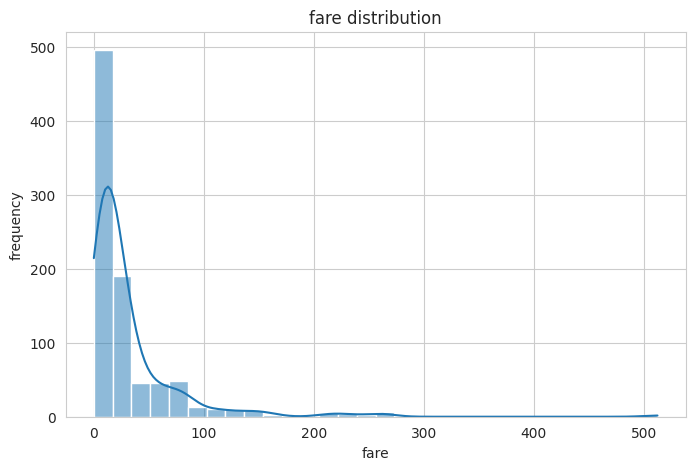

<ipython-input-176-06bddaa21e45>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Fare'], palette='crest')


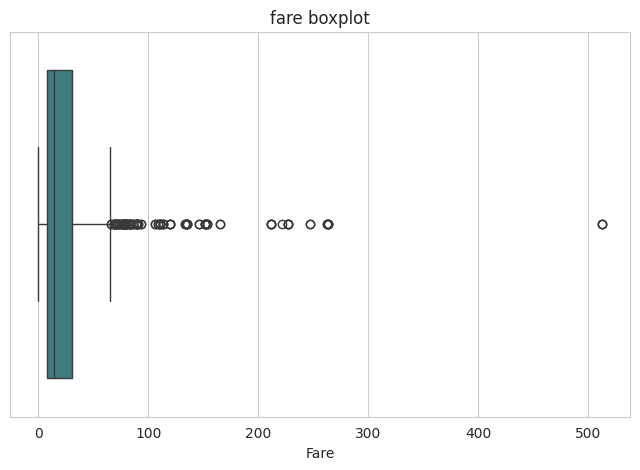

In [176]:
# fare
plt.figure(figsize=(8, 5))
sns.histplot(df['Fare'], kde=True, bins=30)
plt.title("fare distribution")
plt.xlabel("fare")
plt.ylabel("frequency")
plt.show()

print()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Fare'], palette='crest')
plt.title('fare boxplot')
plt.show()

<ipython-input-177-ec4fa6b44cb0>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survived', palette='crest')


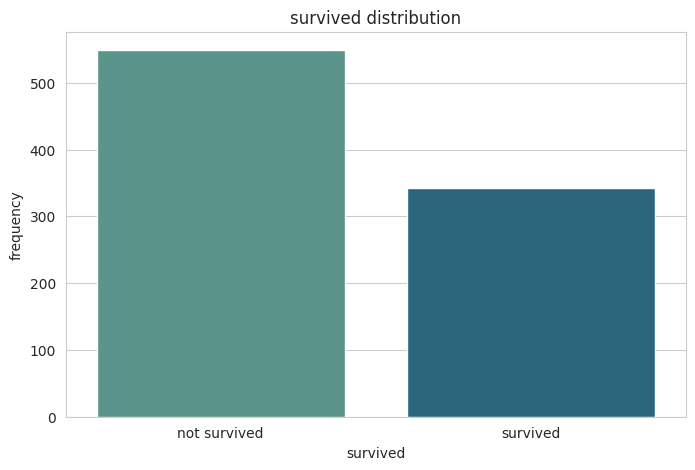

In [177]:
# survived
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Survived', palette='crest')
plt.title('survived distribution')
plt.xticks([0, 1], ['not survived', 'survived'])
plt.xlabel('survived')
plt.ylabel('frequency')
plt.show()

<ipython-input-178-99f9a29f72d6>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pclass', data=df, palette='crest')


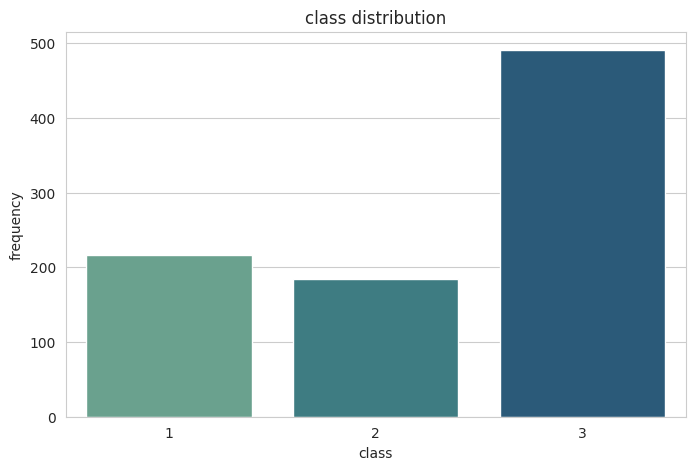

In [178]:
# pclass
plt.figure(figsize=(8, 5))
sns.countplot(x='Pclass', data=df, palette='crest')
plt.title('class distribution')
plt.xlabel('class')
plt.ylabel('frequency')
plt.show()

<ipython-input-179-2032d88b0ee4>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=df, palette='crest')


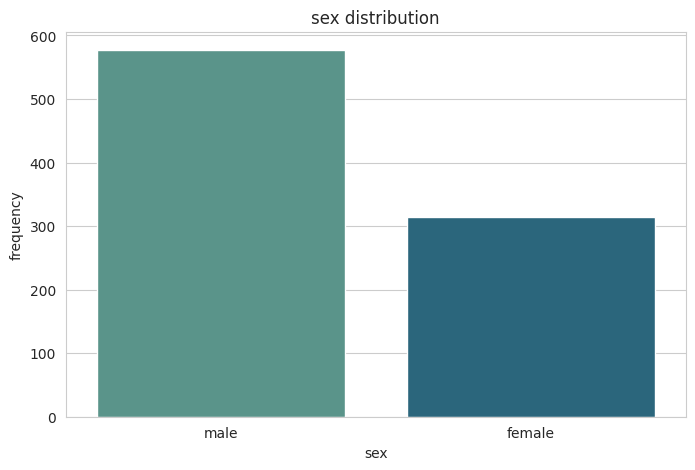

In [179]:
# sex
plt.figure(figsize=(8, 5))
sns.countplot(x='Sex', data=df, palette='crest')
plt.title('sex distribution')
plt.xlabel('sex')
plt.ylabel('frequency')
plt.show()

<ipython-input-180-e57ae674220a>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='SibSp', data=df, palette='crest')


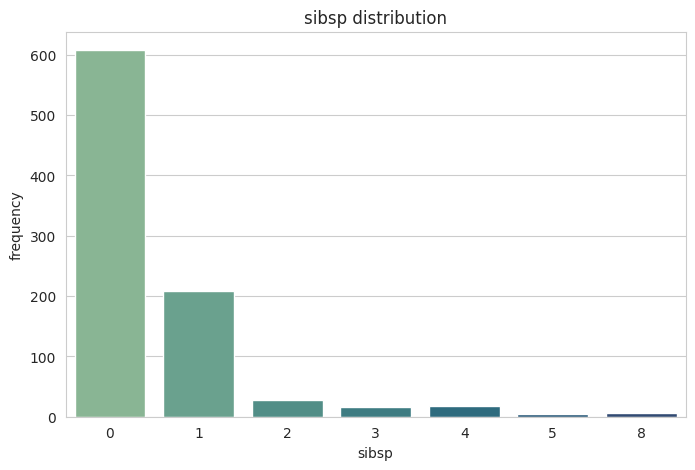

In [180]:
# sibsp
plt.figure(figsize=(8, 5))
sns.countplot(x='SibSp', data=df, palette='crest')
plt.title('sibsp distribution')
plt.xlabel('sibsp')
plt.ylabel('frequency')
plt.show()

<ipython-input-181-e384c46c211d>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Parch', data=df, palette='crest')


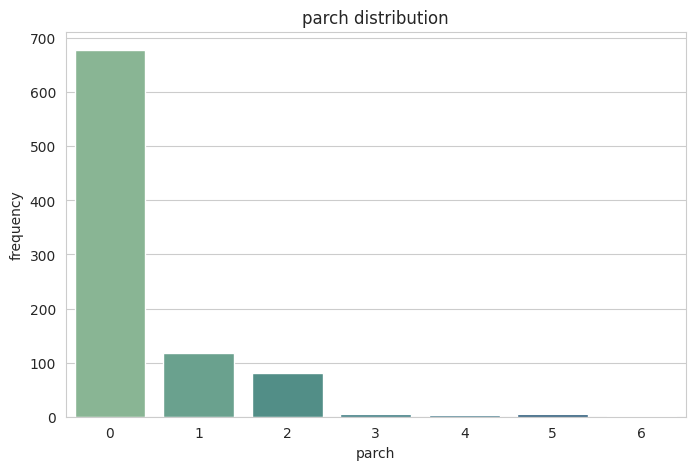

In [181]:
# parch
plt.figure(figsize=(8, 5))
sns.countplot(x='Parch', data=df, palette='crest')
plt.title('parch distribution')
plt.xlabel('parch')
plt.ylabel('frequency')
plt.show()

<ipython-input-182-85a693f0a09c>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Embarked', data=df, palette='crest')


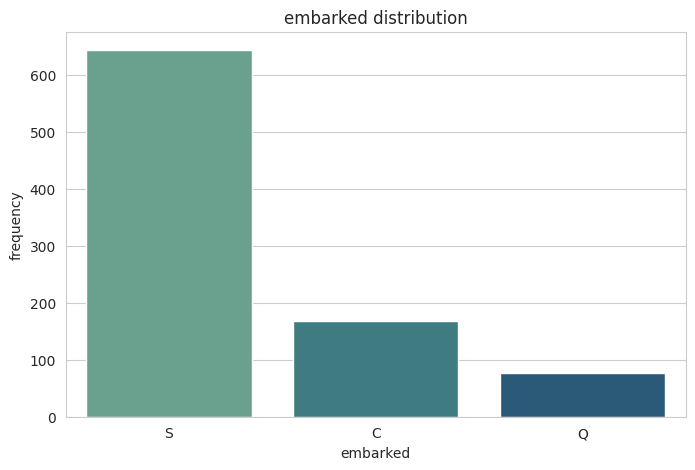

In [182]:
# embarked
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', data=df, palette='crest')
plt.title('embarked distribution')
plt.xlabel('embarked')
plt.ylabel('frequency')
plt.show()

# Relation between data

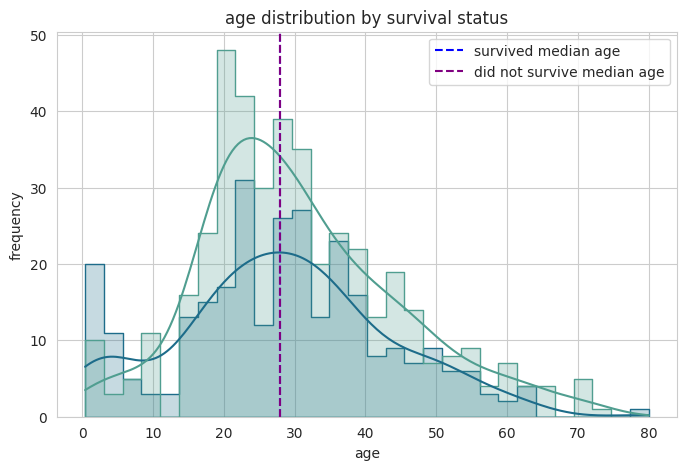

In [183]:
# age and survived
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Survived', element='step', kde=True, palette='crest', bins=30, multiple='layer')
plt.title('age distribution by survival status')
plt.xlabel('age')
plt.ylabel('frequency')
plt.axvline(df[df['Survived']==1]['Age'].median(), color='blue', linestyle='--', label='survived median age')
plt.axvline(df[df['Survived']==0]['Age'].median(), color='purple', linestyle='--', label='did not survive median age')
plt.legend()
plt.show()

<ipython-input-184-3540c8af7e59>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass', y='Age', data=df, palette='crest')


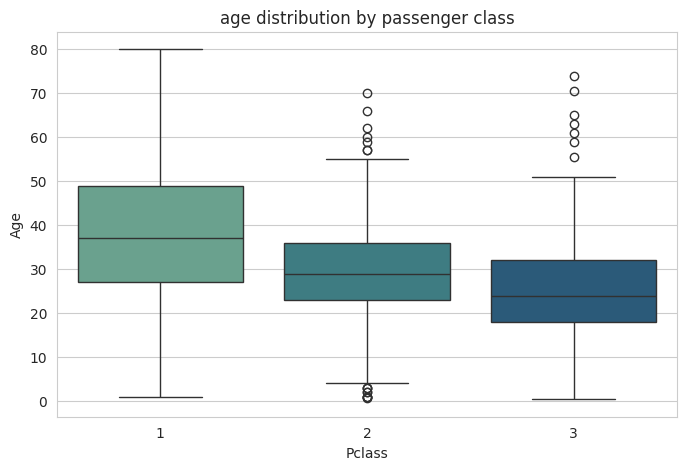

In [184]:
# age and pclass
plt.figure(figsize=(8, 5))
sns.boxplot(x='Pclass', y='Age', data=df, palette='crest')
plt.title('age distribution by passenger class')
plt.show()

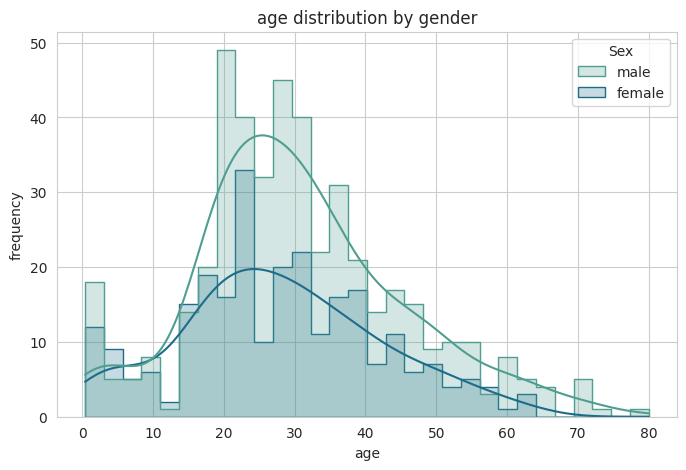

In [185]:
# age and sex
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Sex', element='step', kde=True, palette='crest', bins=30)
plt.title('age distribution by gender')
plt.xlabel('age')
plt.ylabel('frequency')
plt.show()

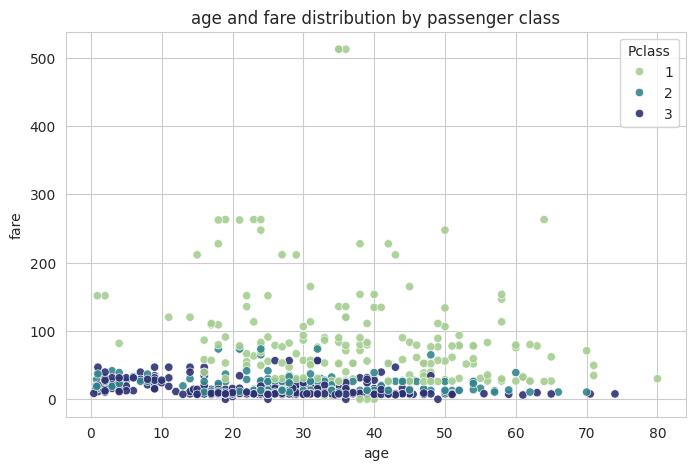

In [186]:
# age and fare
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Age', y='Fare', data=df, hue='Pclass', palette='crest', alpha=0.9)
plt.title('age and fare distribution by passenger class')
plt.xlabel('age')
plt.ylabel('fare')
plt.show()

<ipython-input-187-1ad312008bfc>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, palette='crest')


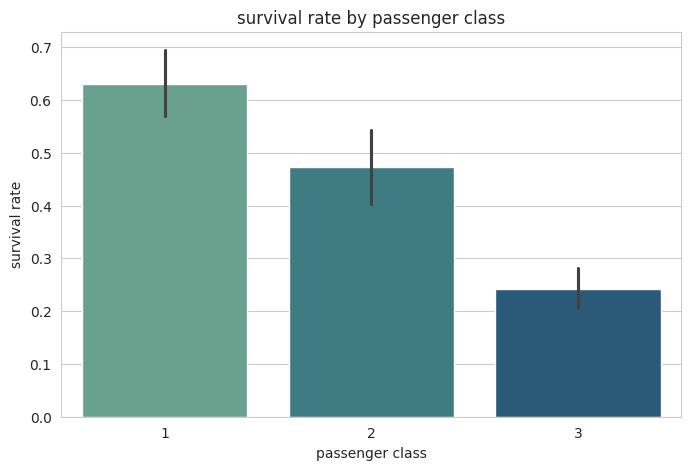

In [187]:
# survived and pclass
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', data=df, palette='crest')
plt.title('survival rate by passenger class')
plt.xlabel('passenger class')
plt.ylabel('survival rate')
plt.show()

<ipython-input-188-587a3289481a>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, palette='crest')


Text(0, 0.5, 'survival rate')

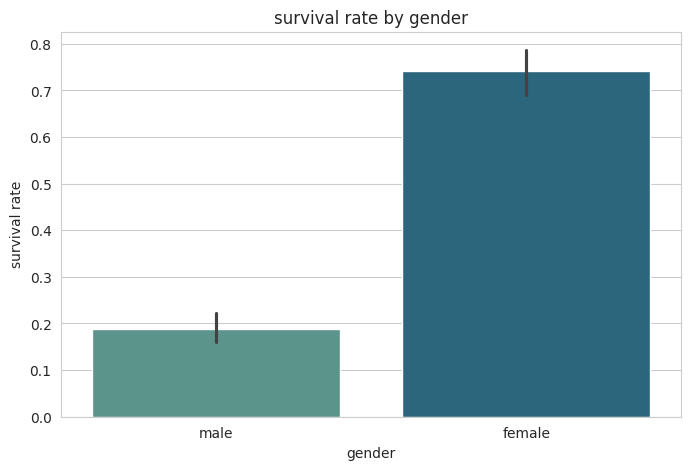

In [188]:
# survived and sex
plt.figure(figsize=(8, 5))
sns.barplot(x='Sex', y='Survived', data=df, palette='crest')
plt.title('survival rate by gender')
plt.xlabel('gender')
plt.ylabel('survival rate')

<ipython-input-189-8deddab2dc74>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Survived', y='Fare', data=df, palette='crest')


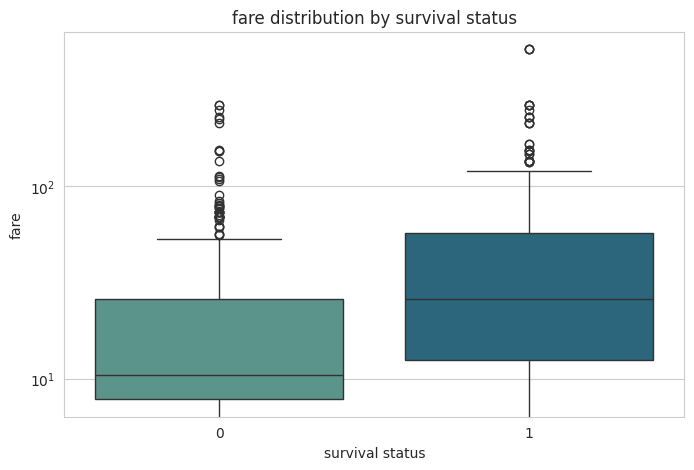

In [189]:
# fare and survived
plt.figure(figsize=(8, 5))
sns.boxplot(x='Survived', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by survival status')
plt.xlabel('survival status')
plt.ylabel('fare')
plt.show()

<ipython-input-190-10f0fd75fbad>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Embarked', y='Survived', data=df, palette='crest')


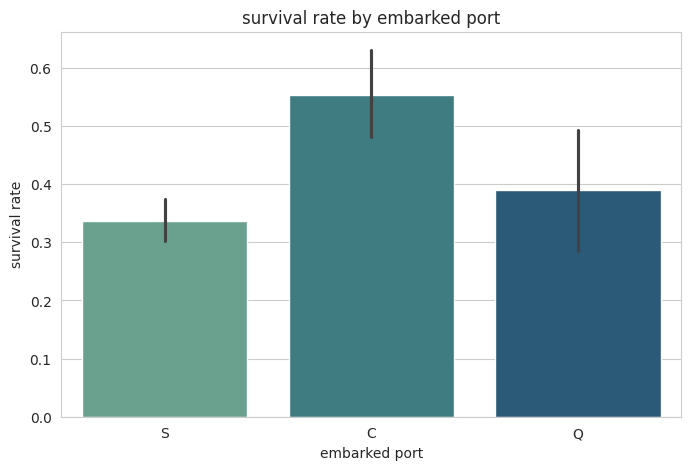

In [190]:
# survived and embarked
plt.figure(figsize=(8, 5))
sns.barplot(x='Embarked', y='Survived', data=df, palette='crest')
plt.title('survival rate by embarked port')
plt.xlabel('embarked port')
plt.ylabel('survival rate')
plt.show()

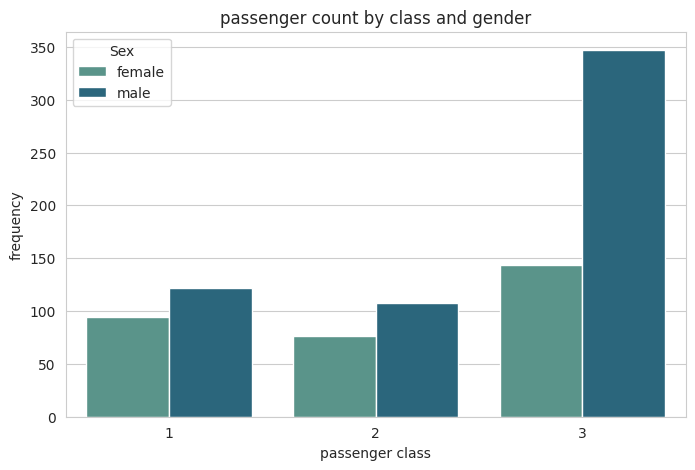

In [191]:
# pclass and sex
plt.figure(figsize=(8, 5))
sns.countplot(x='Pclass', hue='Sex', data=df, palette='crest')
plt.title('passenger count by class and gender')
plt.xlabel('passenger class')
plt.ylabel('frequency')
plt.show()

<ipython-input-192-2d05e51fe9f1>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass', y='Fare', data=df, palette='crest')


Text(0, 0.5, 'fare')

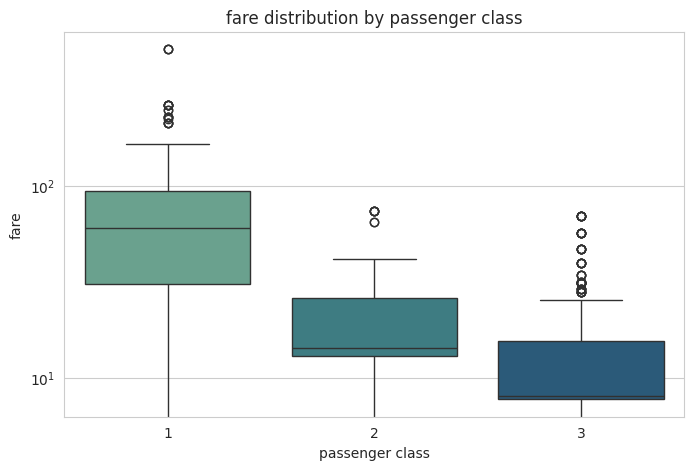

In [192]:
# pclass and fare
plt.figure(figsize=(8, 5))
sns.boxplot(x='Pclass', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by passenger class')
plt.xlabel('passenger class')
plt.ylabel('fare')

<ipython-input-193-0c155f0b0198>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Sex', y='Fare', data=df, palette='crest')


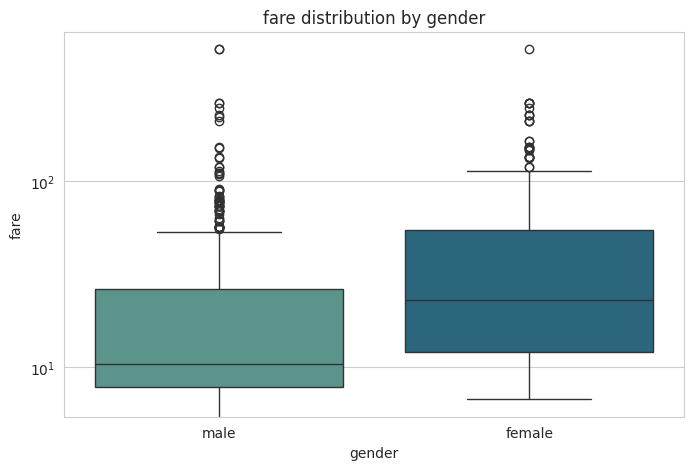

In [193]:
# sex and fare
plt.figure(figsize=(8, 5))
sns.boxplot(x='Sex', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by gender')
plt.xlabel('gender')
plt.ylabel('fare')
plt.show()

<ipython-input-194-3fe52a578e64>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Embarked', y='Fare', data=df, palette='crest')


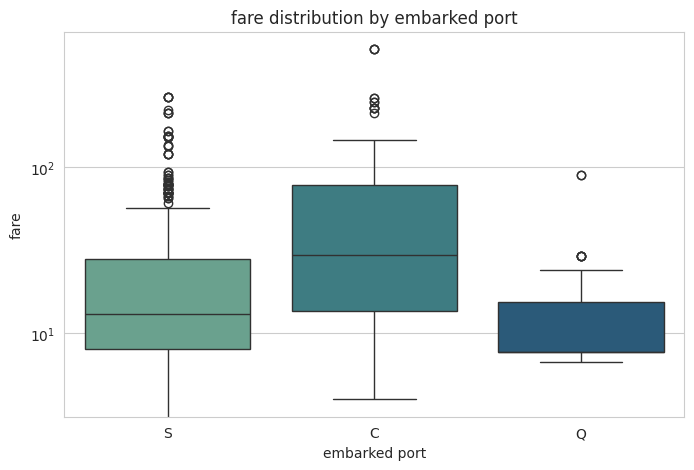

In [194]:
# embarked and fare
plt.figure(figsize=(8, 5))
sns.boxplot(x='Embarked', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by embarked port')
plt.xlabel('embarked port')
plt.ylabel('fare')
plt.show()

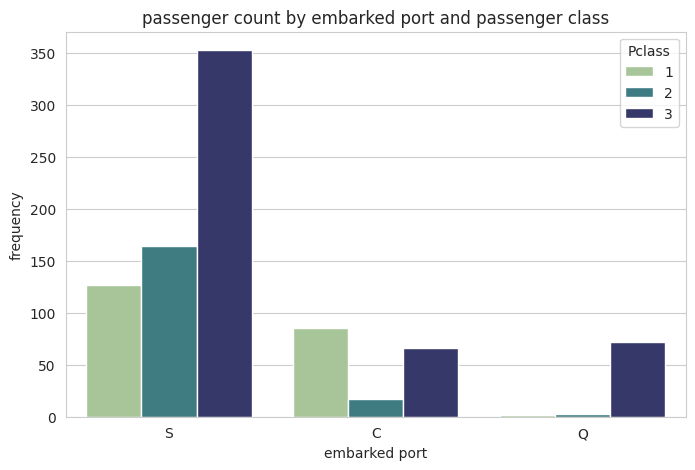

In [195]:
# embarked and pclass
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', hue='Pclass', data=df, palette='crest')
plt.title('passenger count by embarked port and passenger class')
plt.xlabel('embarked port')
plt.ylabel('frequency')
plt.show()

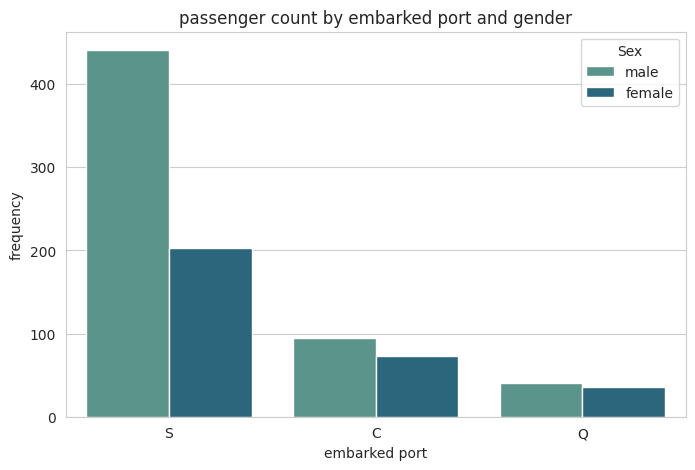

In [196]:
# embarked and sex
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', hue='Sex', data=df, palette='crest')
plt.title('passenger count by embarked port and gender')
plt.xlabel('embarked port')
plt.ylabel('frequency')
plt.show()

<ipython-input-197-ec013eb47399>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='SibSp', y='Survived', data=df, palette='crest')


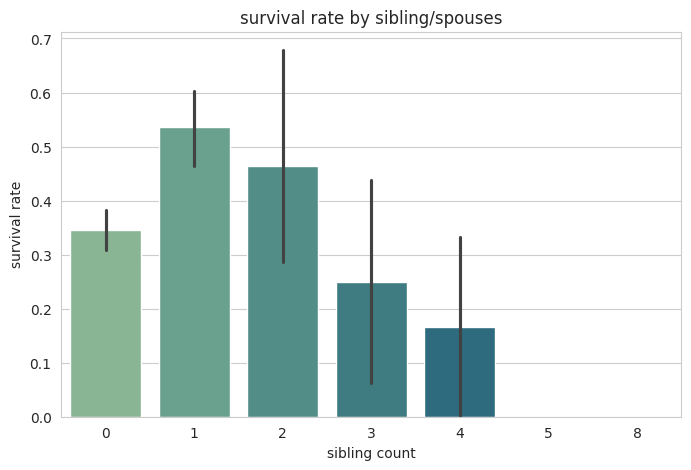

In [197]:
# sibsp and survived
plt.figure(figsize=(8, 5))
sns.barplot(x='SibSp', y='Survived', data=df, palette='crest')
plt.title('survival rate by sibling/spouses')
plt.xlabel('sibling count')
plt.ylabel('survival rate')
plt.show()

<ipython-input-198-3f4e381ac1a1>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Parch', y='Survived', data=df, palette='crest')


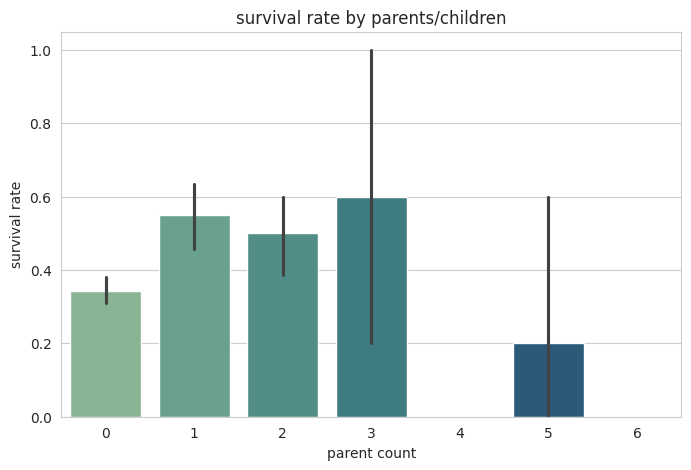

In [198]:
# parch and survived
plt.figure(figsize=(8, 5))
sns.barplot(x='Parch', y='Survived', data=df, palette='crest')
plt.title('survival rate by parents/children')
plt.xlabel('parent count')
plt.ylabel('survival rate')
plt.show()

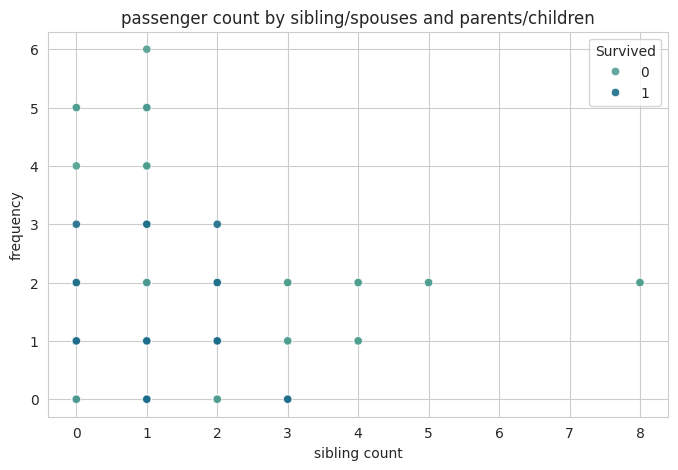

In [199]:
# sibsp and parch
plt.figure(figsize=(8, 5))
sns.scatterplot(x='SibSp', y='Parch', data=df, hue='Survived', palette='crest', alpha=0.9)
plt.title('passenger count by sibling/spouses and parents/children')
plt.xlabel('sibling count')
plt.ylabel('frequency')
plt.show()

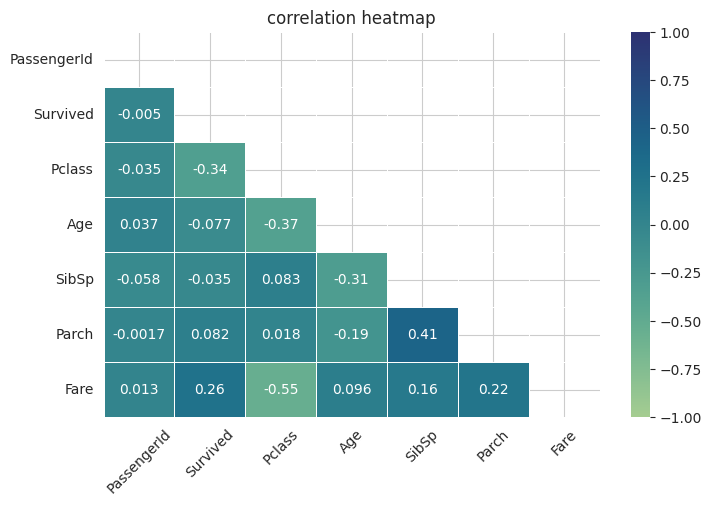

In [200]:
# Correlation heatmap
plt.figure(figsize=(8, 5))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='crest', vmin=-1, vmax=1, linewidths=0.5)
plt.title('correlation heatmap')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# Data Preprocessing

In [210]:
df_clean = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
print(df_clean.head())

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


In [211]:
df_clean['Age'].fillna(df_clean['Age'].median(), inplace=True)

<ipython-input-211-d7551b9a6e63>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['Age'].fillna(df_clean['Age'].median(), inplace=True)


In [212]:
df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0], inplace=True)

<ipython-input-212-40920433c454>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0], inplace=True)


In [213]:
print(df_clean.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [214]:
# convert sex to binary
df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})

In [215]:
# one-hot encode embarked and pclass
df_clean = pd.get_dummies(df_clean, columns=['Embarked', 'Pclass'], drop_first=True)

In [216]:
# feature scaling
scaler = StandardScaler()
scale_cols = ['Age', 'Fare']
df_clean[scale_cols] = scaler.fit_transform(df_clean[scale_cols])

In [217]:
scaler = MinMaxScaler()
scale_cols = ['Age', 'Fare']
df_clean[scale_cols] = scaler.fit_transform(df_clean[scale_cols])

In [218]:
print("Processed Data Shape:", df_clean.shape)
print(df_clean)

Processed Data Shape: (891, 10)
     Survived  Sex       Age  SibSp  Parch      Fare  Embarked_Q  Embarked_S  \
0           0    0  0.271174      1      0  0.014151       False        True   
1           1    1  0.472229      1      0  0.139136       False       False   
2           1    1  0.321438      0      0  0.015469       False        True   
3           1    1  0.434531      1      0  0.103644       False        True   
4           0    0  0.434531      0      0  0.015713       False        True   
..        ...  ...       ...    ...    ...       ...         ...         ...   
886         0    0  0.334004      0      0  0.025374       False        True   
887         1    1  0.233476      0      0  0.058556       False        True   
888         0    1  0.346569      1      2  0.045771       False        True   
889         1    0  0.321438      0      0  0.058556       False       False   
890         0    0  0.396833      0      0  0.015127        True       False   

     Pc